# Food Delivery Time Prediction (ETA) 🚀

**Business Objective:** Deliver accurate, transparent doorstep arrival time estimates (in minutes) for food orders based on order details, courier attributes, road traffic, weather conditions, and spatial coordinates.

### Architectural Principles
1. **Scoping to Checkout-Time ETA**: Excludes actual pickup timestamps and kitchen delay to prevent future-lookahead target leakage. Predicts total duration at the moment of order placement.
2. **Strict Leakage-Free Preprocessing**: Stateless cleaning precedes the 80/20 train/test split. `DeliveryPreprocessor` is embedded directly inside an `sklearn.pipeline.Pipeline`, guaranteeing that imputation, encoding, and scaling are re-fitted strictly within each cross-validation fold.
3. **Strict Batch Invariance**: Uses Scikit-Learn's `OneHotEncoder(handle_unknown='ignore', drop='first')` to ensure predictions on a single order vs. a batch of 1,000 orders are bit-for-bit identical.
4. **Geographic Validation**: Rectifies negative coordinates via `.abs()` (presumed sign errors) and filters unrecorded `(0, 0)` sensor readings.
5. **Unified Codebase**: This notebook calls the exact modular functions and pipeline classes from `src/`.


In [1]:
# Import standard libraries and shared pipeline modules
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Add repository root to path
sys.path.append(os.path.abspath('..'))
from src.data_preprocessing import load_data, clean_data, haversine_distance
from src.feature_engineering import prepare_raw_feature_matrix, DeliveryPreprocessor
from src.model_training import train_and_evaluate, plot_results, save_model, load_model, evaluate_pipeline

print('All shared modules successfully imported from src/')

All shared modules successfully imported from src/


## 1. Data Ingestion & Quality Audit

We load the raw CSV dataset containing 45,593 historical delivery transactions.

In [2]:
df_raw = load_data('../data/delivery_data.csv')
print(f'Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
df_raw.head(3)

Raw dataset shape: 45,593 rows × 20 columns


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

## 2. Coordinate Quality & Sensor Anomaly Detection

India lies entirely in the Northern and Eastern Hemispheres ($8.4^\circ\text{N}$ to $37.6^\circ\text{N}$, $68.7^\circ\text{E}$ to $97.2^\circ\text{E}$).

- **Presumed Sign Errors**: 431 rows contain negative coordinates (e.g. `-12.97°`). These are sensor sign-flip errors; `.abs()` correctly restores them to their true city boundaries.
- **Invalid Coordinates (`0, 0`)**: Exactly 3,640 records have `Restaurant_latitude == 0` and `Restaurant_longitude == 0`. These belong to 50 specific restaurant IDs where GPS hardware was unrecorded (Null Island). Calculating distance produces fake ~8,800 km values. These 3,640 unrecorded sensor records are explicitly filtered out, retaining 41,953 genuine records.

In [4]:
lat1_raw = df_raw['Restaurant_latitude']
lon1_raw = df_raw['Restaurant_longitude']
neg_coords = (lat1_raw < 0) | (lon1_raw < 0)
zero_coords = (lat1_raw == 0) & (lon1_raw == 0)

print(f'Records with negative coordinates (presumed sign errors): {neg_coords.sum()}')
print(f'Records with (0, 0) coordinates (unrecorded sensor failures): {zero_coords.sum()}')

Records with negative coordinates (presumed sign errors): 431
Records with (0, 0) coordinates (unrecorded sensor failures): 3640


## 3. Data Cleaning (Stateless)

Using `clean_data()` from `src/data_preprocessing.py`, we:
1. Normalize text and extract weather/target via regex.
2. Coerce numeric columns and clip rider ratings to the standard `[1.0, 5.0]` scale.
3. Rectify coordinate signs and filter out unrecorded $(0, 0)$ sensor failures.
4. Calculate Haversine distance and extract temporal features (`order_hour`, `day_of_week`, `is_weekend`, `city_code`).

Missing values (NaN) are preserved at this step so that imputation is fitted exclusively on the training split.

In [5]:
df_cleaned = clean_data(df_raw)
print(f'Valid cleaned records: {len(df_cleaned):,} (filtered {len(df_raw) - len(df_cleaned):,} sensor error rows)')
df_cleaned[['distance_km', 'order_hour', 'Time_taken(min)']].describe()

Valid cleaned records: 41,953 (filtered 3,640 sensor error rows)


## 4. Exploratory Data Analysis (EDA)

We analyze the relationships between delivery time and operational variables.

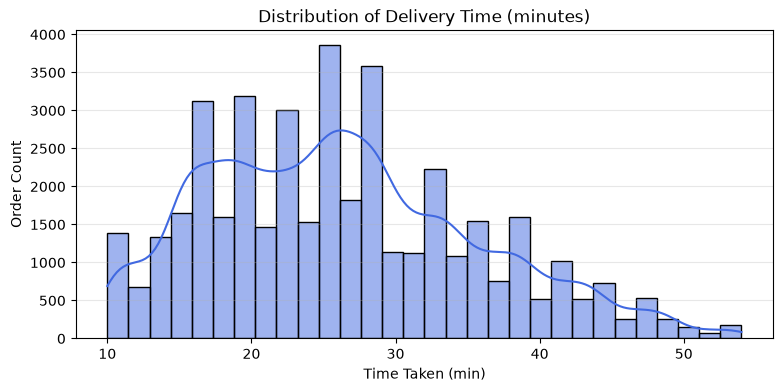

In [6]:
plt.figure(figsize=(9, 4))
sns.histplot(df_cleaned['Time_taken(min)'], kde=True, bins=30, color='royalblue')
plt.title('Distribution of Delivery Time (minutes)')
plt.xlabel('Time Taken (min)')
plt.ylabel('Order Count')
plt.grid(axis='y', alpha=0.3)
plt.show()

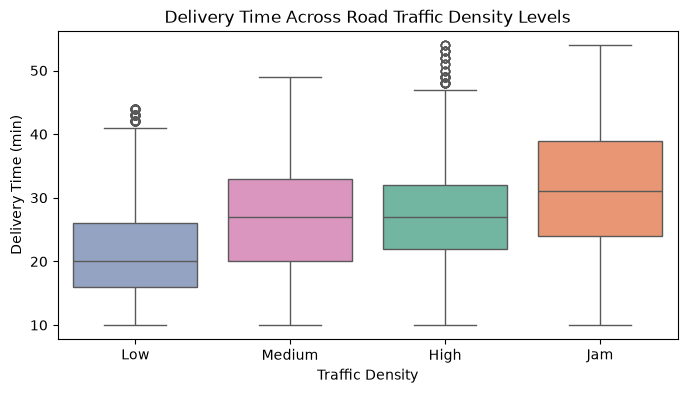

In [7]:
traffic_order = ['Low', 'Medium', 'High', 'Jam']
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_cleaned, x='Road_traffic_density', y='Time_taken(min)', order=traffic_order, hue='Road_traffic_density', legend=False, palette='Set2')
plt.title('Delivery Time Across Road Traffic Density Levels')
plt.xlabel('Traffic Density')
plt.ylabel('Delivery Time (min)')
plt.show()

df_cleaned.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count', 'mean', 'median']).reindex(traffic_order).round(2)

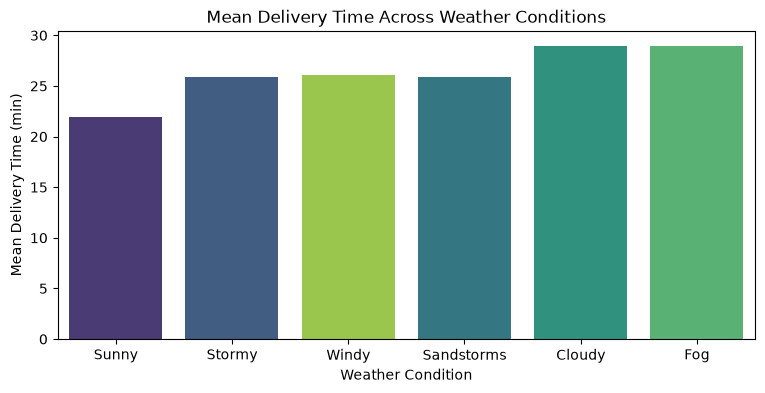

In [8]:
plt.figure(figsize=(9, 4))
weather_order = ['Sunny', 'Stormy', 'Windy', 'Sandstorms', 'Cloudy', 'Fog']
sns.barplot(data=df_cleaned, x='Weatherconditions', y='Time_taken(min)', order=weather_order, hue='Weatherconditions', legend=False, errorbar=None, palette='viridis')
plt.title('Mean Delivery Time Across Weather Conditions')
plt.xlabel('Weather Condition')
plt.ylabel('Mean Delivery Time (min)')
plt.show()

df_cleaned.groupby('Weatherconditions')['Time_taken(min)'].agg(['count', 'mean']).reindex(weather_order).round(2)

In [9]:
print('Delivery Time by Festival Association:')
df_cleaned.groupby('Festival')['Time_taken(min)'].agg(['count', 'mean']).round(2)

Delivery Time by Festival Association:


## 5. Scoping to Checkout-Time ETA (No Target Leakage)

**Prediction Moment**: At checkout, the customer has just placed an order. The courier has not arrived at the restaurant, and the actual pickup timestamp `Time_Order_picked` does not exist yet. Directly using actual `pickup - order` duration would be future-lookahead target leakage. We therefore restrict our feature set strictly to signals available at checkout (15 features).

In [10]:
X_raw, y = prepare_raw_feature_matrix(df_cleaned)
print(f'Checkout-time feature matrix shape: {X_raw.shape}, target shape: {y.shape}')
print(f'Features: {list(X_raw.columns)}')

Checkout-time feature matrix shape: (41953, 15), target shape: (41953,)
Features: ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'order_hour', 'day_of_week', 'is_weekend', 'Vehicle_condition', 'multiple_deliveries', 'Road_traffic_density', 'Weatherconditions', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'city_code']


## 6. Leakage-Free Preprocessing & Batch-Invariance Verification

We split into 80% train ($N=33,562$) and 20% test ($N=8,391$). `DeliveryPreprocessor` is fitted strictly on `X_train_raw`. Below, we run a strict test verifying that predictions on a batch of orders vs. individual orders are 100% identical.

In [11]:
from sklearn.model_selection import train_test_split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42
)
print(f'Train split: {X_train_raw.shape[0]:,} records | Test split: {X_test_raw.shape[0]:,} records')

preprocessor = DeliveryPreprocessor()
preprocessor.fit(X_train_raw)
print(f'Total preprocessed features: {len(preprocessor.feature_names_)}')

# Verify Batch Invariance: transform 5 orders as a batch vs individually
sample_5 = X_test_raw.iloc[:5]
batch_trans = preprocessor.transform(sample_5)
ind_trans = pd.concat([preprocessor.transform(sample_5.iloc[[i]]) for i in range(len(sample_5))])
max_feature_diff = np.max(np.abs(batch_trans.values - ind_trans.values))
print(f'Batch vs Individual transformation maximum absolute diff: {max_feature_diff:.10f}')
assert max_feature_diff < 1e-6, 'Batch invariance assertion failed!'

Train split: 33,562 records | Test split: 8,391 records
Total preprocessed features: 44
Batch vs Individual transformation maximum absolute diff: 0.0000000000


## 7. Model Training with Preprocessing Inside Cross-Validation

We construct Scikit-Learn `Pipeline` objects. For XGBoost hyperparameter tuning, `DeliveryPreprocessor` is placed **inside the pipeline passed to `RandomizedSearchCV`**, ensuring that imputation, encoding, and scaling are re-fitted strictly within each cross-validation fold.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

results = []

# 1. Linear Regression Pipeline
lr_pipe = Pipeline([('preprocessor', DeliveryPreprocessor()), ('regressor', LinearRegression())])
results.append(evaluate_pipeline('Linear Regression', lr_pipe, X_train_raw, X_test_raw, y_train, y_test))

# 2. Decision Tree Pipeline
dt_pipe = Pipeline([('preprocessor', DeliveryPreprocessor()), ('regressor', DecisionTreeRegressor(random_state=42))])
results.append(evaluate_pipeline('Decision Tree', dt_pipe, X_train_raw, X_test_raw, y_train, y_test))

# 3. Random Forest Pipeline
rf_pipe = Pipeline([('preprocessor', DeliveryPreprocessor()), ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
results.append(evaluate_pipeline('Random Forest', rf_pipe, X_train_raw, X_test_raw, y_train, y_test))

# 4. Tuned XGBoost with Preprocessor inside CV
xgb_pipe = Pipeline([('preprocessor', DeliveryPreprocessor()), ('regressor', XGBRegressor(random_state=42, verbosity=0, n_jobs=1, nthread=1))])
xgb_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [3, 5, 7, 9],
    'regressor__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'regressor__subsample': [0.7, 0.8, 1.0],
    'regressor__colsample_bytree': [0.7, 0.8, 1.0],
    'regressor__reg_alpha': [0, 0.1, 0.5],
    'regressor__reg_lambda': [1, 1.5, 2],
}
xgb_search = RandomizedSearchCV(
    xgb_pipe, param_distributions=xgb_param_grid, n_iter=15, scoring='neg_root_mean_squared_error', cv=3, random_state=42, n_jobs=1
)
xgb_search.fit(X_train_raw, y_train)
best_xgb_pipe = xgb_search.best_estimator_
print(f'Best XGBoost Parameters: {xgb_search.best_params_}')
results.append(evaluate_pipeline('XGBoost (Tuned)', best_xgb_pipe, X_train_raw, X_test_raw, y_train, y_test))


  Linear Regression
  Train R²  : 0.5766
  Test  R²  : 0.5683
  Test  RMSE: 6.0984 min
  Test  MAE : 4.8343 min  ← avg error per delivery

  Decision Tree
  Train R²  : 1.0000
  Test  R²  : 0.6402
  Test  RMSE: 5.5679 min
  Test  MAE : 4.2007 min  ← avg error per delivery

  Random Forest
  Train R²  : 0.9735
  Test  R²  : 0.8066
  Test  RMSE: 4.0822 min
  Test  MAE : 3.2275 min  ← avg error per delivery
Best XGBoost Parameters: {'regressor__subsample': 0.7, 'regressor__reg_lambda': 2, 'regressor__reg_alpha': 0.1, 'regressor__n_estimators': 100, 'regressor__max_depth': 9, 'regressor__learning_rate': 0.05, 'regressor__colsample_bytree': 1.0}

  XGBoost (Tuned)
  Train R²  : 0.8626
  Test  R²  : 0.8221
  Test  RMSE: 3.9146 min
  Test  MAE : 3.1163 min  ← avg error per delivery


## 8. Benchmark Visualizations & Performance Comparison

We generate benchmark comparison charts and compile the final metric table.

In [13]:
plot_results(results, y_test, save_path='../outputs/model_comparison.png')

summary_df = pd.DataFrame([{
    'Model': r['name'],
    'Train R²': f"{r['train_r2']:.3f}",
    'Test R²': f"{r['test_r2']:.3f}",
    'Test RMSE (min)': f"{r['test_rmse']:.2f}",
    'Test MAE (min)': f"{r['test_mae']:.2f}"
} for r in results])
summary_df

[*] Comparison plot saved to: ../outputs/model_comparison.png
[*] Actual vs Predicted plot saved to: ../outputs\actual_vs_predicted.png


,Model,Train R²,Test R²,Test RMSE (min),Test MAE (min)
0,Linear Regression,0.577,0.568,6.10,4.83
1,Decision Tree,1.000,0.640,5.57,4.20
2,Random Forest,0.973,0.807,4.08,3.23
3,XGBoost (Tuned),0.863,0.822,3.91,3.12


## 9. Unified Pipeline Serialization & Single-Order Inference

We persist the complete Pipeline bundle using Joblib and verify predictions on raw test orders.

In [14]:
save_model(best_xgb_pipe, best_xgb_pipe.named_steps['preprocessor'].feature_names_, results, path='../models/xgb_model.pkl')

bundle = load_model('../models/xgb_model.pkl')
loaded_pipeline = bundle['pipeline']

# Predict on individual raw orders directly
sample_orders = X_test_raw.iloc[:3]
predictions = loaded_pipeline.predict(sample_orders)

comparison = pd.DataFrame({
    'Actual (min)': y_test.iloc[:3].values,
    'Predicted (min)': np.round(predictions, 2),
    'Absolute Error (min)': np.round(np.abs(y_test.iloc[:3].values - predictions), 2)
})
comparison

[*] Complete pipeline bundle saved using joblib to: ../models/xgb_model.pkl


,Actual (min),Predicted (min),Absolute Error (min)
0,21.0,25.66,4.66
1,18.0,14.68,3.32
2,25.0,25.07,0.07
